---
title: Explorative Datenanalyse
jupyter: python3
---



### Import der benötigen Libaries 

In [12]:
import os
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

#### Import der Rohdaten 

In [13]:
CSV_PATH = "../data/20min_metadaten_keywords.csv"
OUT_DIR = "out_plots"
MIN_ARTICLES_PER_RESSORT = 5  # für Durchschnitts-Plots Ressorts mit >= N Artikeln

os.makedirs(OUT_DIR, exist_ok=True)

df = pd.read_csv(CSV_PATH, dtype=str)

#### Umwandlug und bereinigung der Datentypen

In [14]:
# Datumsfeld robust parsen
df["datum"] = pd.to_datetime(df["datum"], errors="coerce", utc=True)

# Numerische Spalten
for col in ["likes", "kommentare", "shares"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")


# Booleans aus Strings
def to_bool(x):
    if isinstance(x, bool):
        return x
    if isinstance(x, str):
        x = x.strip().lower()
        if x in ("true", "1", "yes"):
            return True
        if x in ("false", "0", "no", ""):
            return False
    return False


df["kommentare_erlaubt"] = df["kommentare_erlaubt"].apply(to_bool)


df["autor"] = df["autor"].fillna("").astype(str)
df["autor"] = df["autor"].str.replace(",", ";")
df["autor"] = df["autor"].str.split(";")
df = df.explode("autor")
df["autor"] = df["autor"].str.strip()

#### Korrektur 

In [15]:
# echte Ressorts definieren
echte_ressorts = {
    "Schweiz",
    "Ausland",
    "Sport",
    "Panorama",
    "Wirtschaft",
    "People",
    "Regionen",
    "Digital",
    "Wissen",
    "Lifestyle",
    "Community",
    "Gesundheit",
    "Coronavirus",
    "Kino & Streaming",
    "Wetter",
    "#WIRSINDZUKUNFT",
}

# Mapping: wenn Ressort nicht in der Liste → Unbekannt
df["ressort"] = df["ressort"].apply(lambda x: x if x in echte_ressorts else "Unbekannt")

#### Überblick 

In [16]:
total = len(df)
zeitraum = (df["datum"].min(), df["datum"].max())
df_authors = df.explode("autor")
df_authors = df_authors[df_authors["autor"].notna() & (df_authors["autor"] != "")]
n_authors = df_authors["autor"].nunique()
n_ressorts = df["ressort"].nunique()
share_comments_enabled = df["kommentare_erlaubt"].mean() if total else 0.0
top_ressorts = df["ressort"].value_counts().head(17)

print(f"Artikel gesamt: {total}")
print(f"Zeitraum: {zeitraum[0]}  →  {zeitraum[1]}")
print(f"Anzahl unterschiedlicher Autoren: {n_authors}")
print(f"Anzahl Ressorts: {n_ressorts}")
print(f"Anteil kommentierbar: {share_comments_enabled:.1%}")
print("\nRessorts (nach Anzahl):")
print(top_ressorts)

Artikel gesamt: 481076
Zeitraum: 2003-10-01 02:42:00+00:00  →  2025-09-29 13:20:00+00:00
Anzahl unterschiedlicher Autoren: 6546
Anzahl Ressorts: 17
Anteil kommentierbar: 19.2%

Ressorts (nach Anzahl):
ressort
Schweiz             125645
Ausland              70996
Sport                67665
Panorama             54998
Wirtschaft           37369
People               37130
Regionen             31696
Digital              14219
Lifestyle            13126
Wissen               12487
Unbekannt             7148
Community             3076
Gesundheit            2544
Coronavirus           1575
Kino & Streaming       555
Wetter                 473
#WIRSINDZUKUNFT        374
Name: count, dtype: int64


In [17]:
# Autoren-Spalte in Listen aufspalten
df_authors = df.copy()
df_authors["autor"] = df_authors["autor"].fillna("").astype(str).str.split(";")

# Jede/n Autor:in in eigene Zeile bringen
df_authors = df_authors.explode("autor")

# Whitespace bereinigen (erst casten!)
df_authors["autor"] = df_authors["autor"].astype(str).str.strip()

# Leere oder 'nan'-Einträge raus
df_authors = df_authors[
    (df_authors["autor"] != "") & (df_authors["autor"].str.lower() != "nan")
]

df["autor"] = df["autor"].replace(
    {"": "Unbekannt", "Undefined Undefined ": "Unbekannt"}
)
# Top 20 Autor:innen
top_autoren = df_authors["autor"].value_counts().head(20)

print("\nTop 20 Autor:innen (nach Anzahl Artikel):")
print(top_autoren)

# Gesamtanzahl verschiedener Autor:innen
n_autoren = df_authors["autor"].nunique()
print(f"\nGesamtanzahl unterschiedlicher Autor:innen: {n_autoren}")


Top 20 Autor:innen (nach Anzahl Artikel):
autor
Undefined Undefined        16182
Chk                         5043
Kle                         4185
SDA                         3809
Fee                         2994
Nils Hänggi                 2967
Jonas Bucher                2935
Karin Leuthold              2766
Sda                         2624
Woz                         2558
Benedikt Hollenstein        2453
Justin Arber                2448
Florian Osterwalder         2414
Sven Forster                2412
Heg                         2207
Deutsche Presse-Agentur     2120
Vro                         2116
Fabian Pöschl               2106
Fal                         1986
Als                         1976
Name: count, dtype: int64

Gesamtanzahl unterschiedlicher Autor:innen: 6546


#### Artikel pro Monat 

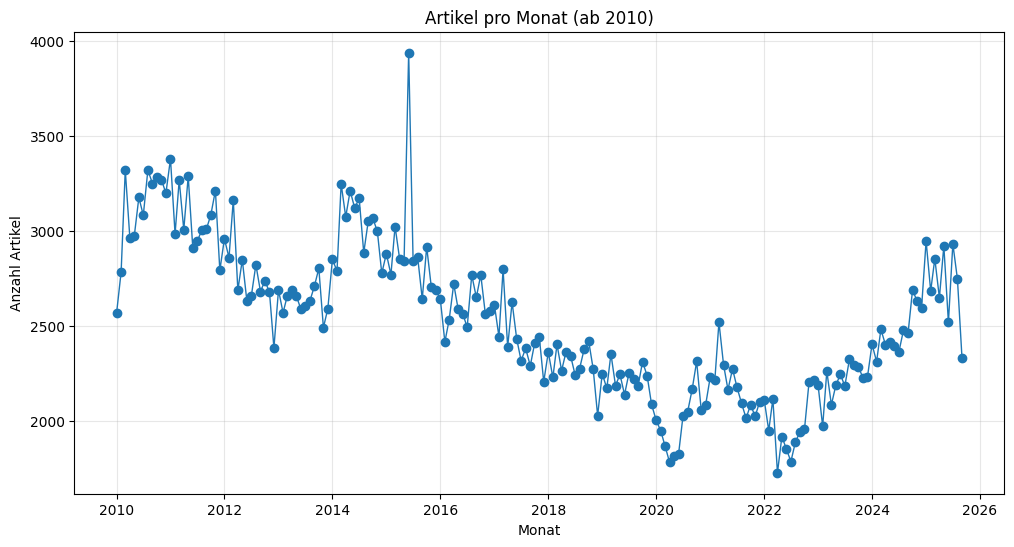

In [18]:
df_after_2010 = df[df["datum"].dt.year >= 2010]
# Artikel pro Monat zählen
monthly_counts = df_after_2010.set_index("datum").resample("MS").size()

# Plot
plt.figure(figsize=(12, 6))
plt.plot(monthly_counts.index, monthly_counts.values, marker="o", linewidth=1)
plt.title("Artikel pro Monat (ab 2010)")
plt.xlabel("Monat")
plt.ylabel("Anzahl Artikel")
plt.grid(True, alpha=0.3)
plt.show()

#### Entwicklung der anzahl Artikel in den top 5 Ressorts ab 2010

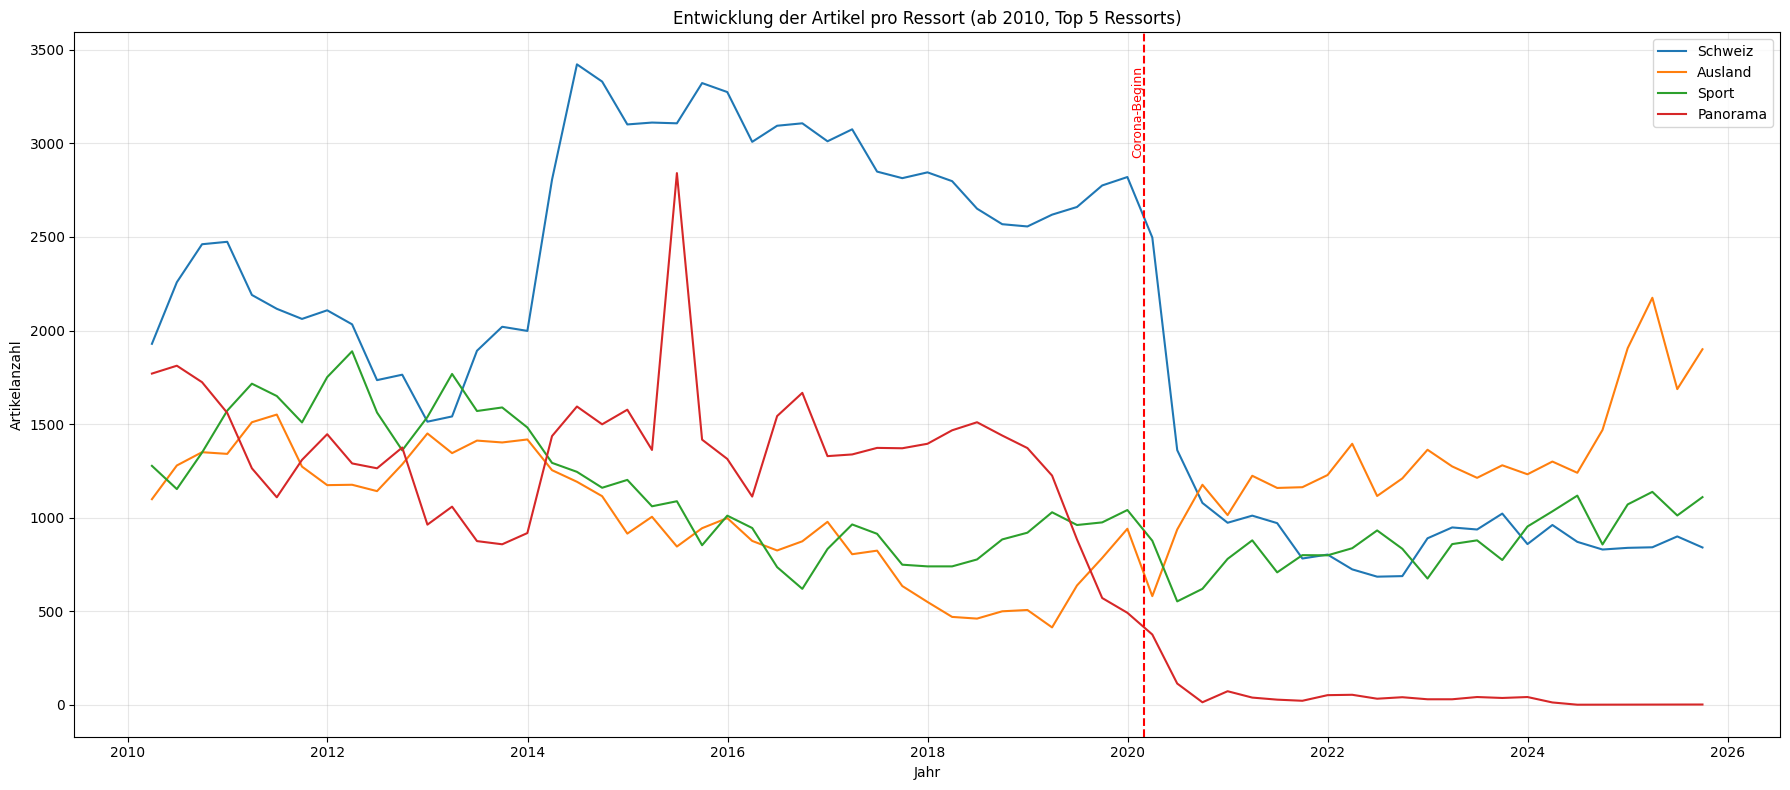

In [19]:
# Beispiel: ab 2010, Artikel pro Monat und Ressort zählen
df_filtered = df[df["datum"] >= "2010-01-01"]

monthly_ressort = (
    df_filtered.groupby(["ressort", pd.Grouper(key="datum", freq="QE")])
    .size()
    .reset_index(name="anzahl")
)

# Top 4 Ressorts nach Gesamtanzahl
top_ressorts = df_filtered["ressort"].value_counts().head(4).index

fig, ax = plt.subplots(figsize=(18, 8))

for ressort in top_ressorts:
    data = monthly_ressort[monthly_ressort["ressort"] == ressort]
    ax.plot(data["datum"], data["anzahl"], label=ressort)

# --- Vertikale Linien hinzufügen ---
wichtige_daten = {
    "Corona-Beginn": "2020-03-01",
}

for label, datum in wichtige_daten.items():
    ax.axvline(pd.to_datetime(datum), color="red", linestyle="--", linewidth=1.5)
    ax.text(
        pd.to_datetime(datum),
        ax.get_ylim()[1] * 0.95,
        label,
        rotation=90,
        color="red",
        ha="right",
        va="top",
        fontsize=9,
    )

# Formatierung
ax.set_title("Entwicklung der Artikel pro Ressort (ab 2010, Top 5 Ressorts)")
ax.set_xlabel("Jahr")
ax.set_ylabel("Artikelanzahl")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Entwicklung Likes, Shares und Kommentare ab 2021

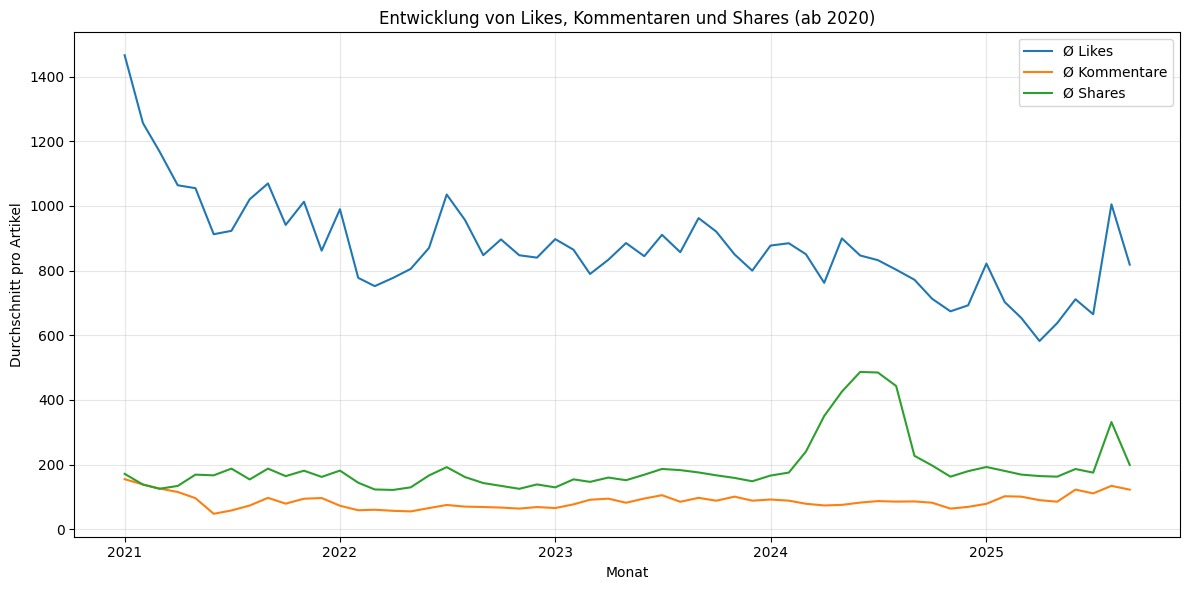

In [20]:
# sicherstellen, dass likes/kommentare/shares numerisch sind
for col in ["likes", "kommentare", "shares"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")


monthly_mean = (
    df[df["datum"].dt.year >= 2021]
    .set_index("datum")
    .resample("MS")[["likes", "kommentare", "shares"]]
    .mean()
)

# Plot
plt.figure(figsize=(12, 6))
plt.plot(monthly_mean.index, monthly_mean["likes"], label="Ø Likes", color="tab:blue")
plt.plot(
    monthly_mean.index,
    monthly_mean["kommentare"],
    label="Ø Kommentare",
    color="tab:orange",
)
plt.plot(
    monthly_mean.index, monthly_mean["shares"], label="Ø Shares", color="tab:green"
)

plt.title("Entwicklung von Likes, Kommentaren und Shares (ab 2020)")
plt.xlabel("Monat")
plt.ylabel("Durchschnitt pro Artikel")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Anteil der kommendierbaren Beiträge ab 2021

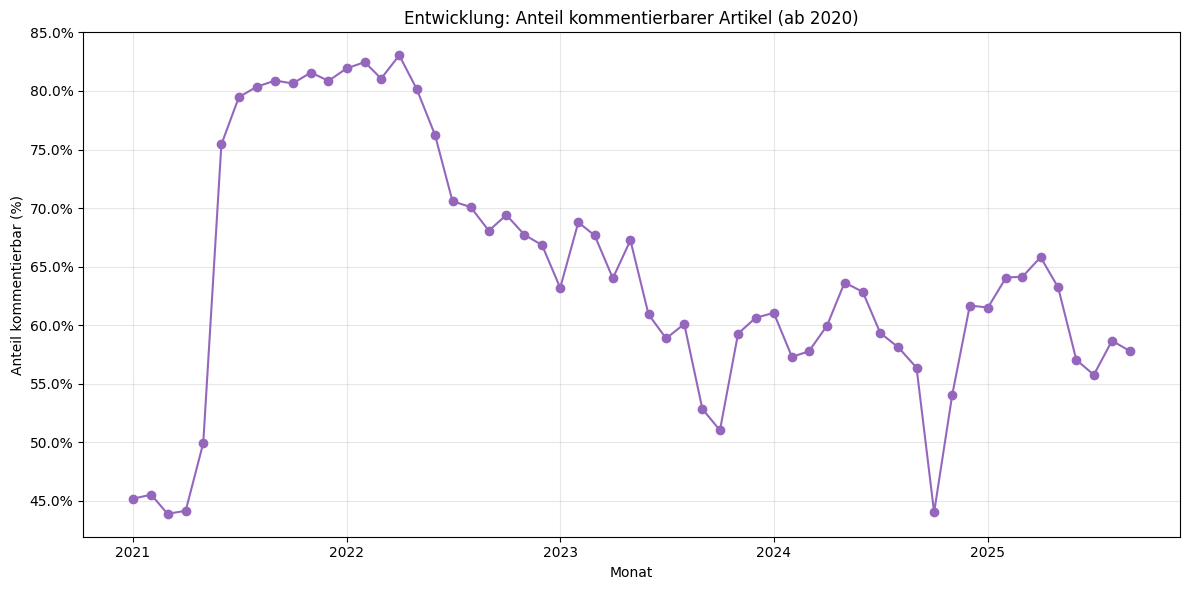

In [21]:
monthly_flag = (
    df[df["datum"].dt.year >= 2021]
    .set_index("datum")
    .resample("MS")["kommentare_erlaubt"]
    .mean()
    * 100
)

# Plot
plt.figure(figsize=(12, 6))
plt.plot(
    monthly_flag.index,
    monthly_flag.values,
    marker="o",
    linestyle="-",
    color="tab:purple",
)
plt.title("Entwicklung: Anteil kommentierbarer Artikel (ab 2020)")
plt.xlabel("Monat")
plt.ylabel("Anteil kommentierbar (%)")
plt.grid(True, alpha=0.3)

# Y-Achse als Prozent formatieren
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter())

plt.tight_layout()
plt.show()

#### Anteil komentierbare Artikel pro Ressort ab 2021

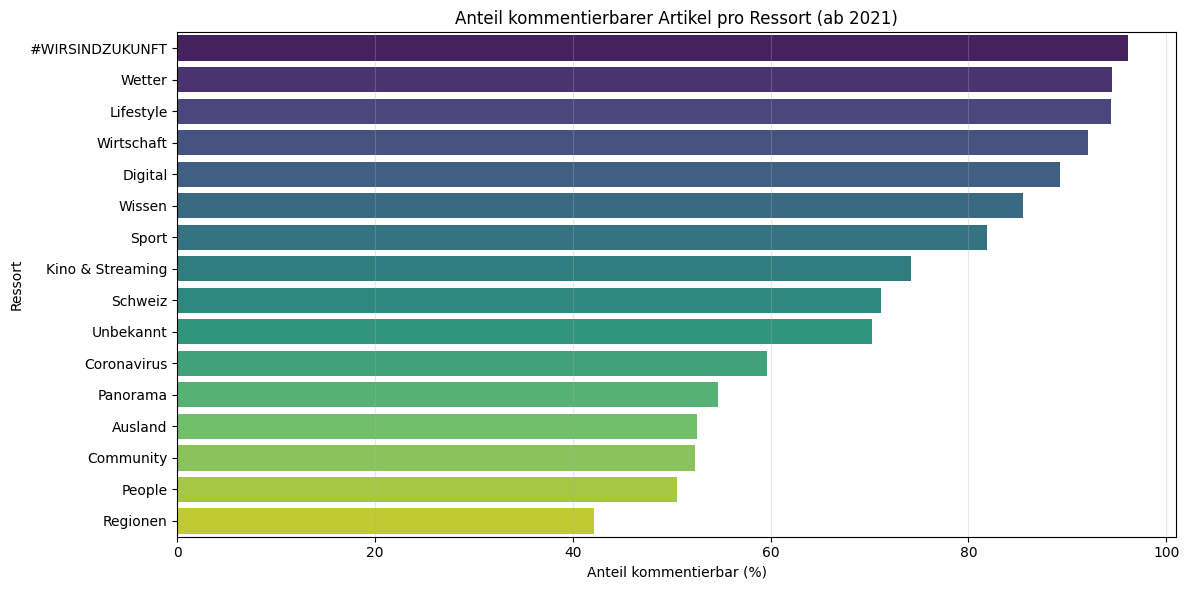

In [22]:
df_2021 = df[df["datum"].dt.year >= 2021]

# Anteil kommentierbarer Artikel pro Ressort (in %)
ressort_comment_share = (
    df_2021.groupby("ressort")["kommentare_erlaubt"].mean().sort_values(ascending=False)
    * 100
)

# Optional: nur Ressorts mit mindestens 100 Artikeln berücksichtigen
valid_ressorts = df_2021["ressort"].value_counts()[lambda x: x >= 100].index
ressort_comment_share = ressort_comment_share.loc[
    ressort_comment_share.index.isin(valid_ressorts)
]

plt.figure(figsize=(12, 6))
sns.barplot(
    x=ressort_comment_share.values,
    y=ressort_comment_share.index,
    hue=ressort_comment_share.index,  # <- das ist neu
    palette="viridis",
    legend=False,  # <- Legende abschalten
)
plt.title("Anteil kommentierbarer Artikel pro Ressort (ab 2021)")
plt.xlabel("Anteil kommentierbar (%)")
plt.ylabel("Ressort")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

kommentär pro ressort in abhängikeit der zeit 
